**Reading note.** This notebook records the Week 6 analysis. Later held-out tests did not find a consistent forecasting advantage for the MPS gauges. See [the final findings](../week7/FINDINGS.md) before interpreting these charts as risk signals.


# The Complexity / Fragility gauge (Δ_HO): methodology, results, and portfolio use

**Risk question: how much joint structure lies beyond covariance right now?** The Complexity gauge asks two model families the same predictive question and reports the gap — the value of dependence a covariance matrix cannot express. Classical cousin: the Kritzman–Li absorption ratio. Honest framing up front: this gauge is ~50% redundant with the classical panel — its role is *corroboration plus a higher-order layer*, not novelty. (Five books here: banks, primary, semis, cross-asset, GFC — the daily walk-forward series was not run for crypto.)

## 1 — How the model behind this gauge is trained

**The pipeline, per portfolio.** Daily prices $\to$ log returns. A **252-trading-day window**
slides through the sample in **10-day steps**. Inside each window:

1. **Discretization.** Each asset's returns are cut into $d=12$ quantile bins on the window
   (bin 1 = that asset's worst days, bin 12 = its best). The model learns the joint distribution
   of the $N$ bin symbols.
2. **Chain ordering.** Assets are arranged on a 1-D chain by **Fiedler ordering of the pairwise
   mutual-information matrix**, computed once from the *first 250 days only* and frozen — the
   ordering never sees the future.
3. **The model.** A **matrix-product-state (MPS) Born machine**:

$$P(x_1,\dots,x_N) \;=\; \frac{\left|\psi(x_1,\dots,x_N)\right|^2}{Z},
\qquad
\psi(x_1,\dots,x_N) \;=\; A^{(1)}_{x_1}\,A^{(2)}_{x_2}\cdots A^{(N)}_{x_N},$$

   where each $A^{(i)}_{x_i}$ is a $\chi\times\chi$ matrix selected by asset $i$'s bin symbol
   ($1\times\chi$ and $\chi\times 1$ at the chain ends) and $Z$ normalizes over all $12^N$
   configurations — computed exactly by tensor contraction, never by enumeration.
   **Bond dimension $\chi = 8$**: the information bandwidth passed along the chain
   ($\chi=1$ would make all assets independent; Week-7's capacity study swept $\chi$ up to 24 and
   sized it out of sample).
4. **Training: two-site DMRG** (density-matrix renormalization group) minimizing the negative
   log-likelihood

$$\mathcal{L} \;=\; -\frac{1}{T}\sum_{t=1}^{T}\ln P(x_t)
\;=\; -\frac{1}{T}\sum_{t=1}^{T}\Big[\,2\ln\left|\psi(x_t)\right| - \ln Z\,\Big],$$

   sweeping left$\to$right$\to$left over adjacent tensor pairs (**8 sweeps**), solving each local
   two-site subproblem with **L-BFGS (20 inner iterations)**, in **mixed-canonical form** (which
   makes $Z=\lVert T\rVert^2$ exact and cheap). Two implementation details that matter:
   the fit is **cold-started** (a cold random start empirically captures more cross-correlation
   than warm-starting from an Adam pre-fit), and per-sample environment vectors are
   **row-normalized** to prevent geometric underflow on chains of $N\ge 16$ assets.

Everything is causal: window $t$'s fit sees only window $t$'s days; bin edges, ordering, and all
model parameters are window-local. One fit $\to$ one gauge reading $\to$ the rolling series below.


## 2 — The gauge, in math

**Δ_HO, the same-measure walk-forward contrast.** Four models are fitted per window and scored on
the **held-out predictive log-likelihood** $\ell$ of the days after the window (walk-forward,
causal): the Born machine at $\chi=8$ (sees any dependence), the Born machine at $\chi=1$ (sees
none), a full-covariance Gaussian (sees linear dependence), and a diagonal Gaussian (sees none).

$$\Delta_{HO}(t) \;=\;
\underbrace{\Big[\ell^{\mathrm{Born}}_{\chi=8}(t) - \ell^{\mathrm{Born}}_{\chi=1}(t)\Big]}_{\text{value of ALL dependence}}
\;-\;
\underbrace{\Big[\ell^{\mathrm{Gauss}}_{\mathrm{full}}(t) - \ell^{\mathrm{Gauss}}_{\mathrm{diag}}(t)\Big]}_{\text{value of LINEAR dependence}},$$

smoothed with a 21-day moving average. Subtracting **within each family** first is what makes the
discrete (binned) Born scores and continuous Gaussian densities comparable — the bin-width terms
cancel exactly inside the first bracket (the "same-measure" fix, BUG-LOG #18a). Units: nats/day of
predictive log-likelihood. $\Delta_{HO}\approx 0$: covariance describes the joint behavior;
$\Delta_{HO}>0$: predictive structure beyond covariance.

**The cousin — the absorption ratio** (Kritzman–Li). With $\lambda_1 \ge \dots \ge \lambda_N$ the
eigenvalues of the window's correlation matrix,

$$AR(t) \;=\; \frac{\sum_{k=1}^{\lceil N/5 \rceil} \lambda_k}{\sum_{k=1}^{N} \lambda_k},$$

the share of variance absorbed by the top fifth of the eigenvectors — high = tightly coupled =
fragile, built entirely from covariance.

In [1]:
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import pathlib

pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
plt.rcParams.update({'figure.facecolor': 'white', 'axes.grid': True, 'grid.alpha': .3,
                     'axes.spines.top': False, 'axes.spines.right': False})
CORAL, BLUE, GREY = '#ec5a2e', '#3d97dc', '#8a949e'
DATA = pathlib.Path(os.environ.get("DATA_EXT", "../data"))
RES = pathlib.Path('../analysis/results')

CRISES = [('2011-07','2012-02'),('2015-08','2015-10'),('2018-10','2018-12'),
          ('2020-02','2020-05'),('2022-01','2022-10'),('2023-03','2023-05')]
def shade(ax):
    for a, b in CRISES:
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color='red', alpha=.07)
def z(s): return (s - s.mean()) / s.std()

BOOKS = 'dhi'
GAUGE_NAME, COUSIN_NAME = 'Complexity (Δ_HO)', 'absorption ratio'

## 3 — Loading the five portfolios and computing both indicators

For each book: the gauge series comes from the committed rolling run; the classical cousin is
computed here from the same book's returns with the standard formula, on the same causal windows.

**Index-book disclosure:** the S&P Top 50 and DJIA books use *current* index membership filtered
to names with continuous data since 2006 (DJIA: 29 of 30 — V listed in 2008; S&P Top 50: the 50
largest current names that traded through 2006). Fixed membership back-cast this way carries
survivorship bias toward winners, which *inflates buy-and-hold* and therefore biases the
comparison **against** the de-risking dials — the conservative direction for our claims. Both
samples include the 2007–09 GFC and the 2022 bear.

In [2]:
GAUGE_COL = 'delta_ho_sm'
DHI = {
    'S&P Top 50 (50 mega-caps, 2006+)': ('sp50_prices', 'dhi_sp50_prices_delta'),
    'DJIA (29 of 30 members, 2006+)': ('djia_prices', 'dhi_djia_prices_delta'),
    'Banks (15 stocks)': ('banks_prices', 'dhi_banks_prices_delta'),
    'Primary (24 diversified stocks)': ('primary_prices', 'dhi_primary_prices_delta'),
    'Semis (15 stocks)': ('semis_prices', 'dhi_semis_prices_delta'),
    'Crypto (11 coins)': ('crypto_cm_prices', 'dhi_crypto_cm_prices_delta'),
    'X-asset + BTC (crypto-equity mix)': ('combined_crossasset_2026_lagbtc', 'dhi_combined_crossasset_2026_lagbtc_delta'),
    'GFC book (12 ETFs)': ('combined_gfc_2026', 'dhi_combined_gfc_2026_delta'),
}
WIN = 252

def load_returns(stem):
    px = pd.read_parquet(DATA / f'{stem}.parquet').astype(float)
    return np.log(px).diff().dropna()

loaded = {}
for name, (stem, dhi_stem) in DHI.items():
    rets = load_returns(stem)
    ew = rets.mean(axis=1)
    gauge = pd.read_csv(RES / f'{dhi_stem}.csv', parse_dates=['date']).set_index('date')[GAUGE_COL].dropna()
    # absorption ratio, daily, trailing 252d
    X = rets.to_numpy(); n_eig = max(1, round(rets.shape[1] / 5))
    vals = np.full(len(rets), np.nan)
    for t in range(WIN, len(rets)):
        ev = np.sort(np.linalg.eigvalsh(np.corrcoef(X[t - WIN:t].T)))[::-1]
        vals[t] = ev[:n_eig].sum() / ev.sum()
    cousin = pd.Series(vals, index=rets.index).dropna()
    loaded[name] = {'ew': ew, 'gauge': gauge, 'cousin': cousin}
    print(f'{name:36s} gauge: {len(gauge):5d} daily obs  {gauge.index.min().date()} -> {gauge.index.max().date()}')

S&P Top 50 (50 mega-caps, 2006+)     gauge:  4809 daily obs  2007-06-04 -> 2026-07-15


DJIA (29 of 30 members, 2006+)       gauge:  4809 daily obs  2007-06-04 -> 2026-07-15


Banks (15 stocks)                    gauge:  4297 daily obs  2009-06-01 -> 2026-06-30


Primary (24 diversified stocks)      gauge:  3188 daily obs  2013-10-17 -> 2026-06-23


Semis (15 stocks)                    gauge:  3895 daily obs  2011-01-03 -> 2026-06-30
Crypto (11 coins)                    gauge:  1792 daily obs  2021-08-10 -> 2026-07-06


X-asset + BTC (crypto-equity mix)    gauge:  3639 daily obs  2011-12-13 -> 2026-06-15


GFC book (12 ETFs)                   gauge:  4530 daily obs  2008-06-26 -> 2026-06-30


## 4 — The indicator, book by book: ours, the cousin, and the overlay

Three panels per book: the raw gauge, the raw cousin, and both z-scored on one axis (crises
shaded). Expect broad-strokes agreement — both are coupling meters, and ~50% mutual redundancy is the measured overlap — with Δ_HO departing where the co-movement's *shape* changes while its linear strength does not.

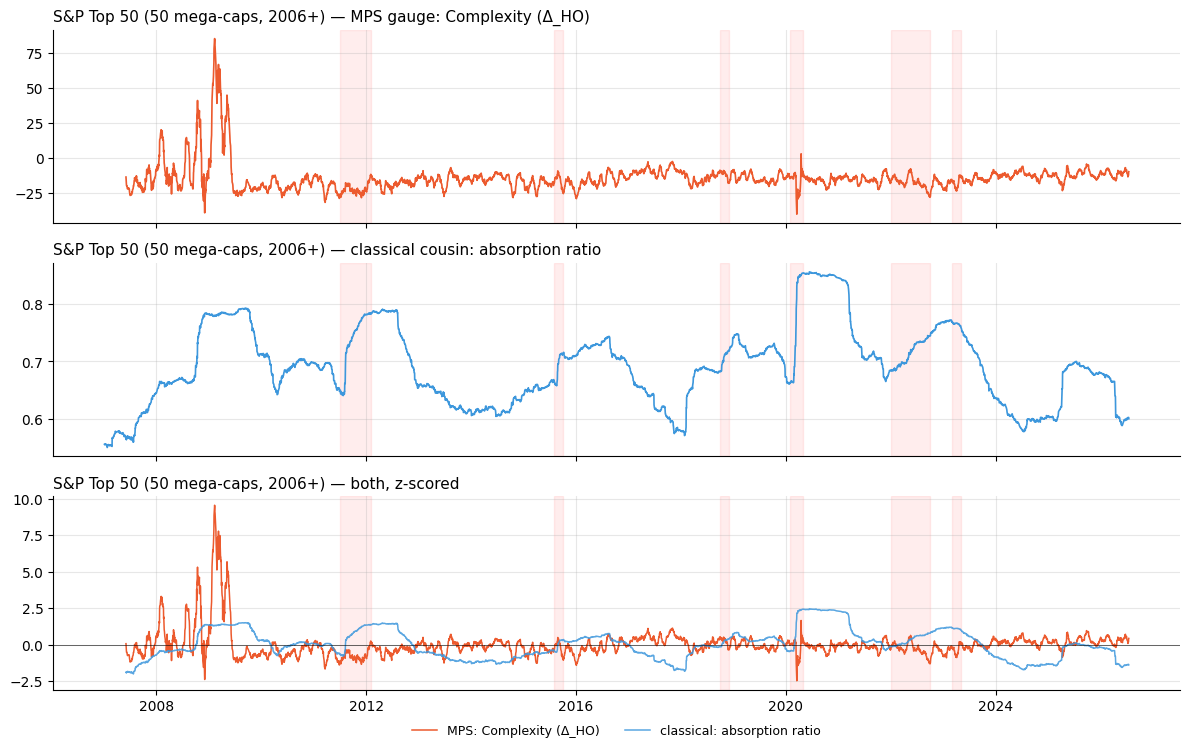

S&P Top 50 (50 mega-caps, 2006+): correlation(gauge, cousin) = +0.01  |  observations = 4809


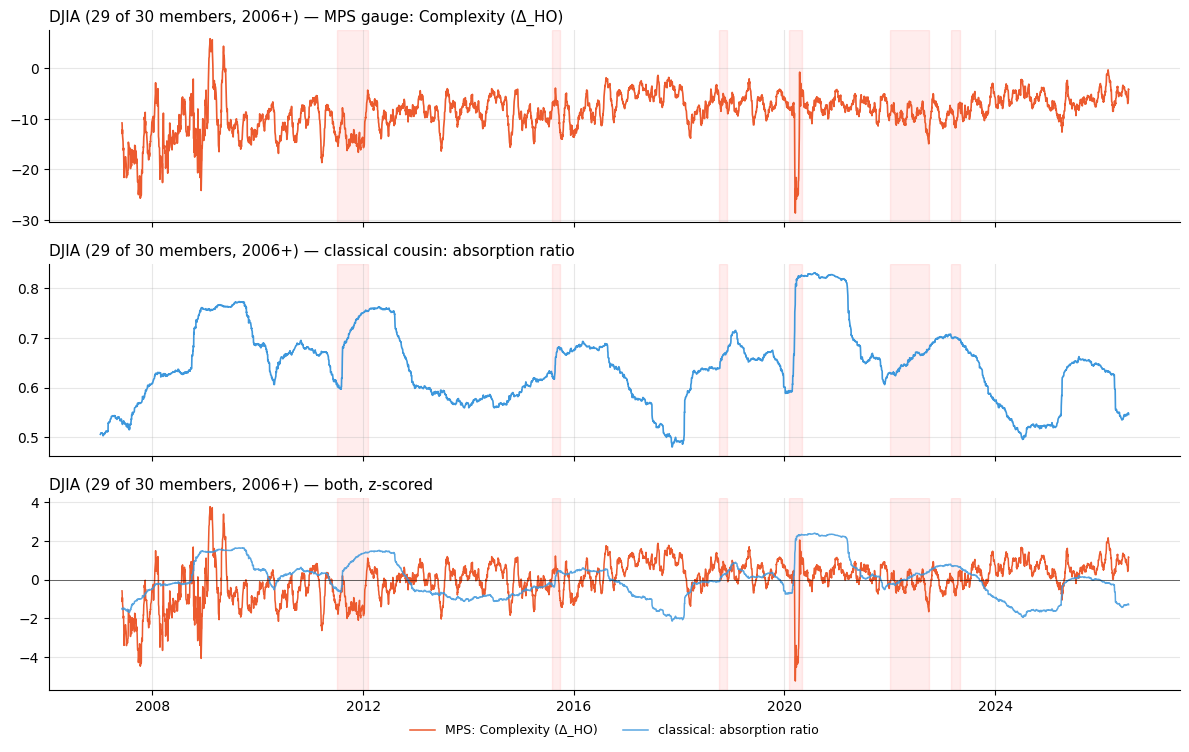

DJIA (29 of 30 members, 2006+): correlation(gauge, cousin) = -0.16  |  observations = 4809


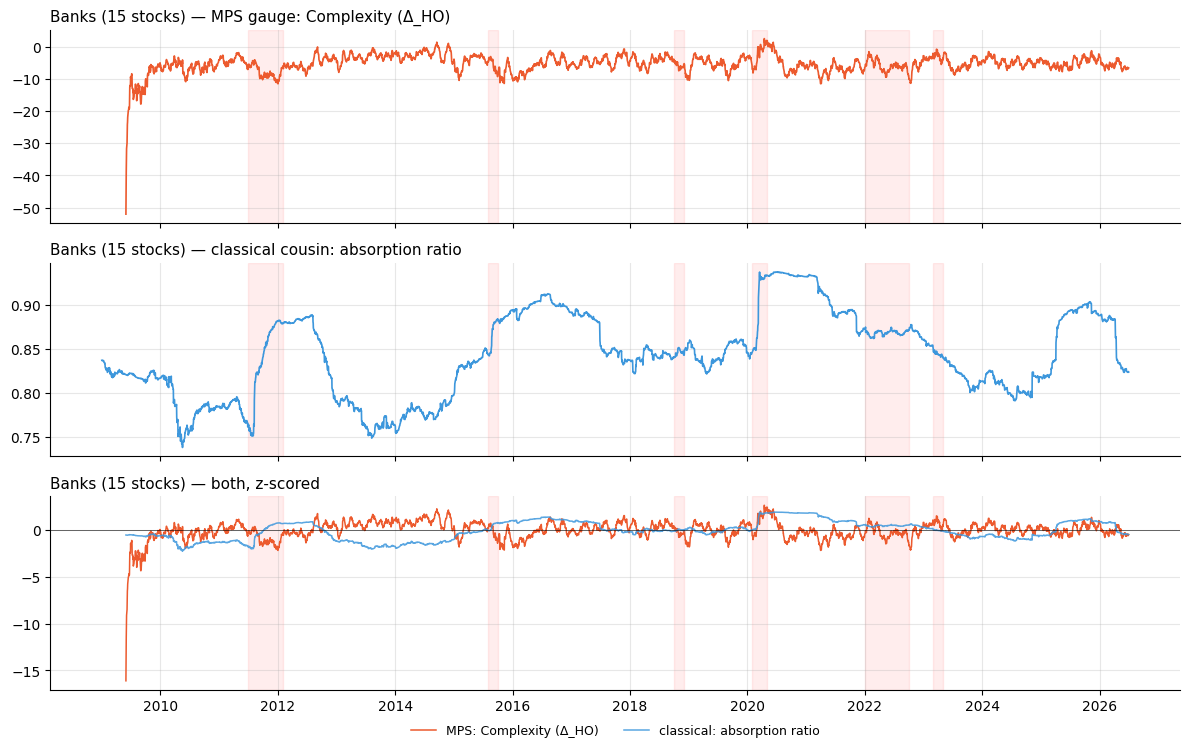

Banks (15 stocks): correlation(gauge, cousin) = -0.14  |  observations = 4297


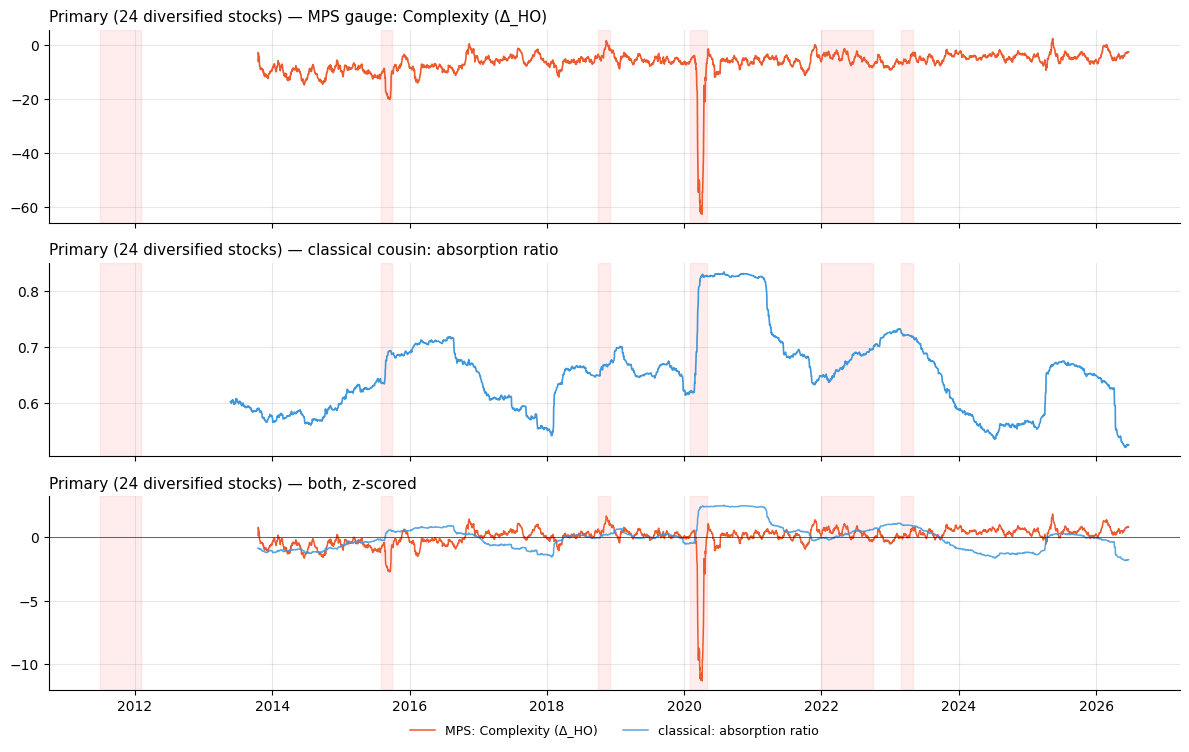

Primary (24 diversified stocks): correlation(gauge, cousin) = -0.18  |  observations = 3188


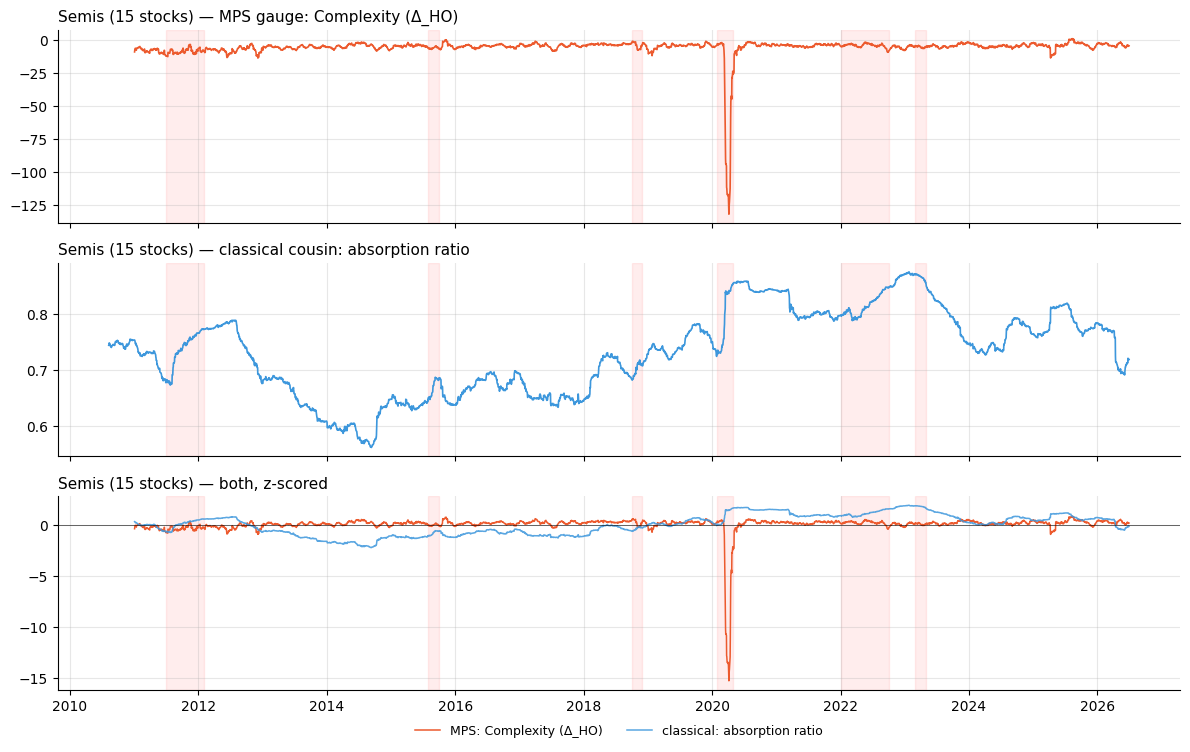

Semis (15 stocks): correlation(gauge, cousin) = -0.12  |  observations = 3895


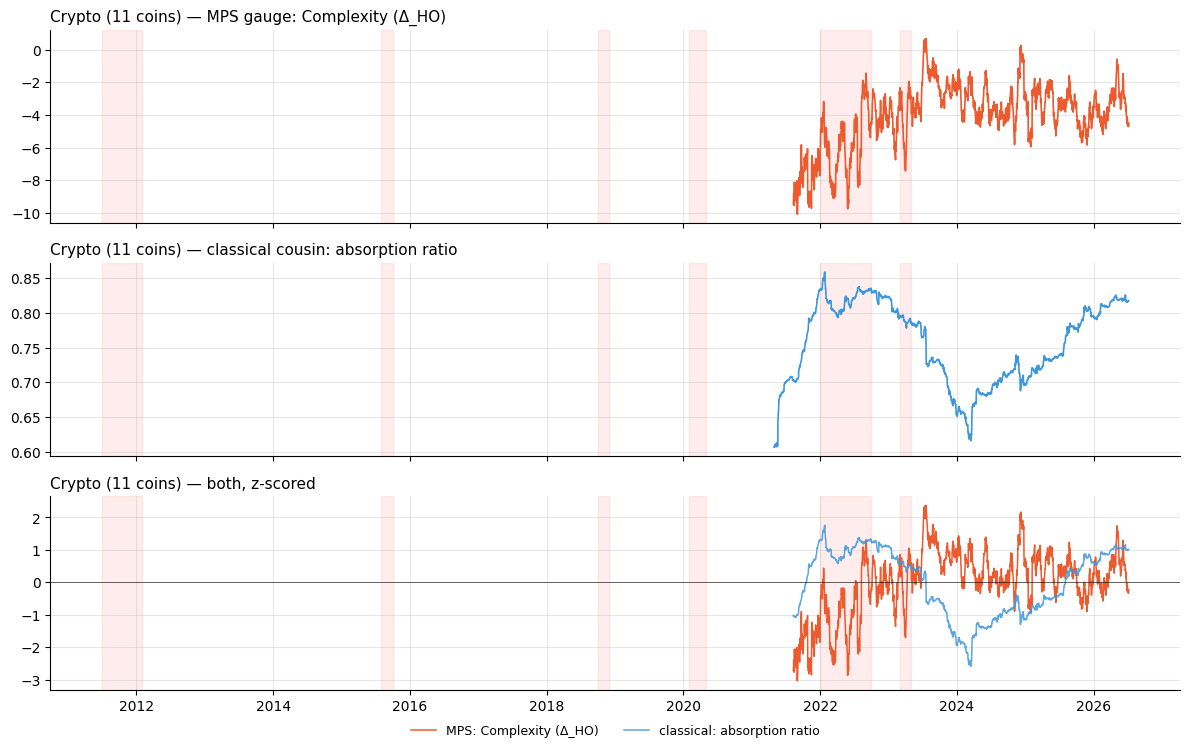

Crypto (11 coins): correlation(gauge, cousin) = -0.31  |  observations = 1792


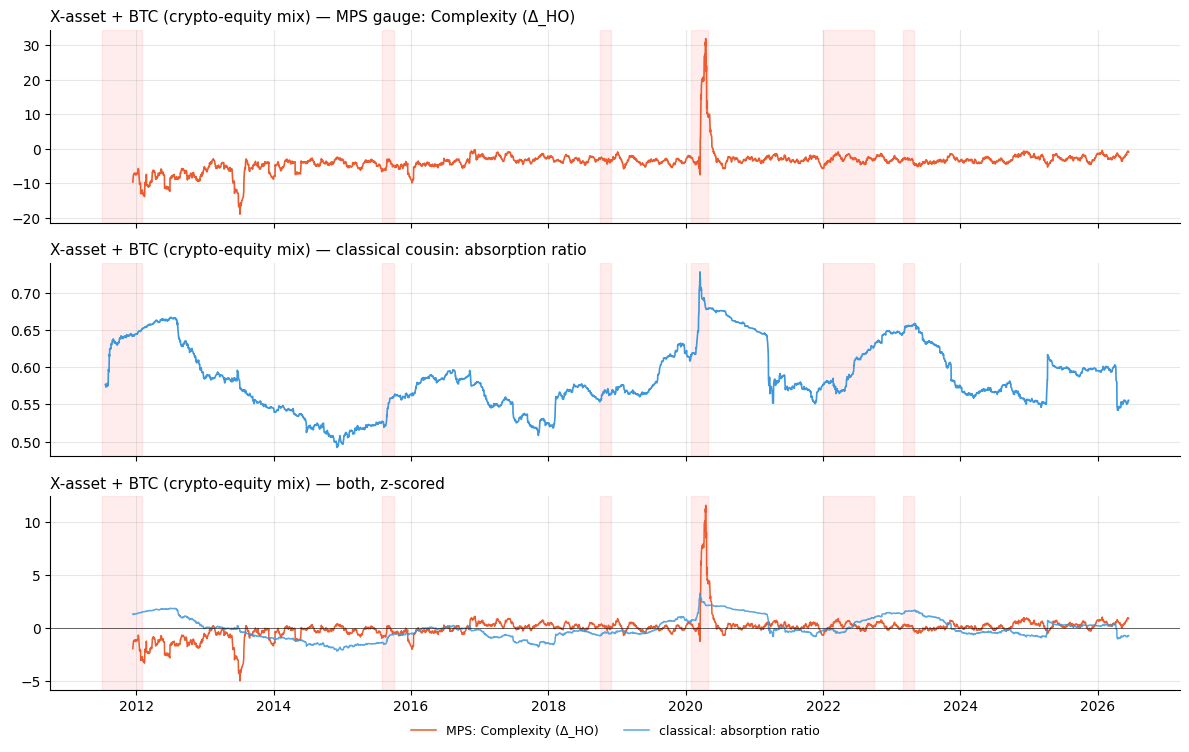

X-asset + BTC (crypto-equity mix): correlation(gauge, cousin) = +0.04  |  observations = 3639


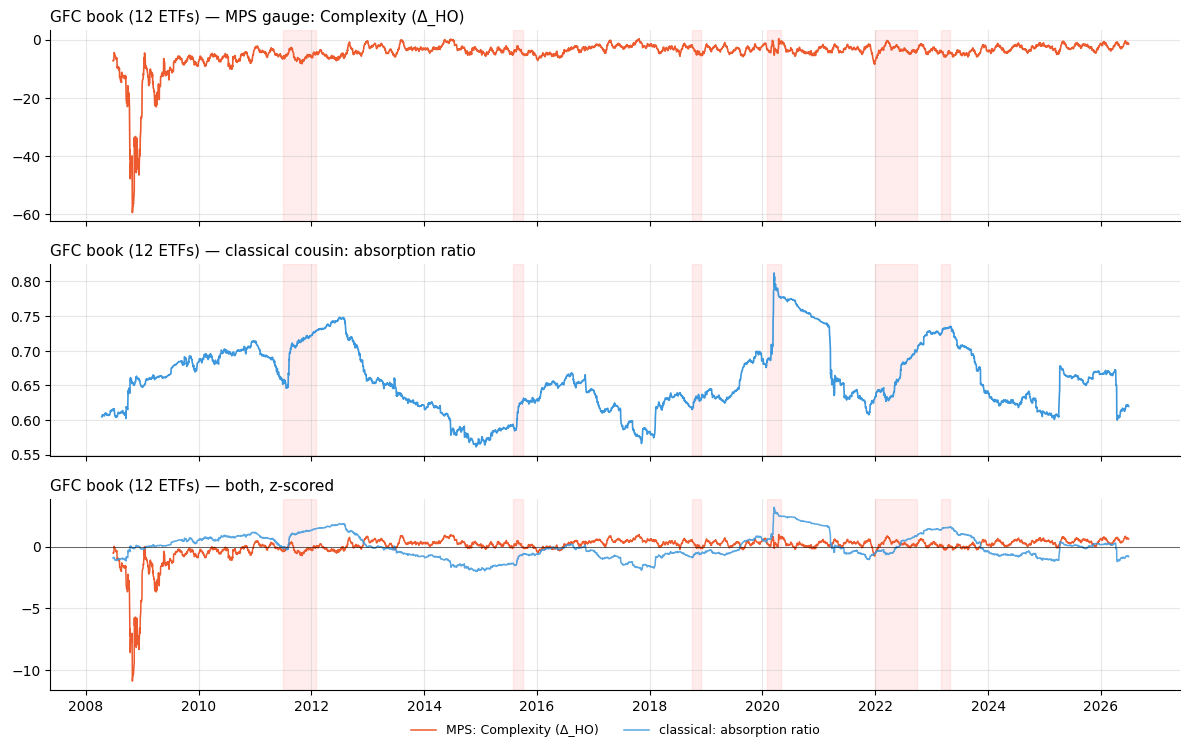

GFC book (12 ETFs): correlation(gauge, cousin) = -0.09  |  observations = 4530


In [3]:
for name, dd in loaded.items():
    g, c = dd['gauge'], dd['cousin']
    fig, axes = plt.subplots(3, 1, figsize=(12, 7.6), sharex=True)
    axes[0].plot(g.index, g.values, color=CORAL, lw=1.2)
    axes[0].set_title(f'{name} — MPS gauge: {GAUGE_NAME}', loc='left', fontsize=11)
    axes[1].plot(c.index, c.values, color=BLUE, lw=1.2)
    axes[1].set_title(f'{name} — classical cousin: {COUSIN_NAME}', loc='left', fontsize=11)
    common = g.index.intersection(c.index)
    axes[2].plot(common, z(g.loc[common]).values, color=CORAL, lw=1.1, label=f'MPS: {GAUGE_NAME}')
    axes[2].plot(common, z(c.loc[common]).values, color=BLUE, lw=1.1, alpha=.85,
                 label=f'classical: {COUSIN_NAME}')
    axes[2].axhline(0, color='k', lw=.4)
    axes[2].set_title(f'{name} — both, z-scored', loc='left', fontsize=11)
    axes[2].legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False, fontsize=9)
    for ax in axes: shade(ax)
    plt.tight_layout(); plt.show()
    rho = z(g.loc[common]).corr(z(c.loc[common]))
    print(f'{name}: correlation(gauge, cousin) = {rho:+.2f}  |  observations = {len(common)}')

## Economic interpretation

Δ_HO answers a model-governance question a risk desk actually faces: **is my covariance-based risk
stack currently adequate?** Near zero, correlation-based VaR, risk parity, and diversification
arithmetic describe the world about as well as anything can. Elevated, the joint distribution
carries predictive structure those tools cannot represent — the regime where Gaussian VaR breach
rates drift above target and stress scenarios need explicit co-crash mass. Because it broadly
tracks the absorption ratio (by design — both are coupling meters), its honest use is as
**corroboration with a higher-order overlay**: when both rise, fragility is confirmed; when Δ_HO
rises alone, the change is in the dependence *shape*, which the absorption ratio cannot see.

## 5 — Portfolio value, exactly as portfoliooptimizer.io Figure 3

The blog's actual Figure-3 strategy is a **continuous** allocation, not an on/off switch: convert
the indicator into a percentile of its own history and glide exposure accordingly,

$$s_t \;=\; \operatorname{PercentileRank}\big(x_t \,\big|\, x_{1:t}\big), \qquad
w_t \;=\; 1 - s_t,$$

allocating $w_t$ to the equal-weight book and $1-w_t$ to a **bond sleeve** (long-Treasury ETF,
TLT):

$$r^{\mathrm{strategy}}_t \;=\; w_t\, r^{\mathrm{book}}_t \;+\; (1-w_t)\, r^{\mathrm{bonds}}_t.$$

Percentile rank uses the expanding history up to $t$ (minimum one year), weekly rebalancing, the
exposure applied from the next trading day, no transaction costs. For reference, the stats table
also includes **Kritzman's original 0/50/100 rule** with the proper standardized shift — the
fast-vs-slow average difference
$z_t = \big(\bar{x}_{15d} - \bar{x}_{1y}\big)/\hat{\sigma}_{1y}$, exposure 0% above $+1$, 100%
below $-1$, 50% otherwise.

**Read it with Week-7 discipline:** these gauges are descriptive, not predictive; judge by
drawdown avoided per unit of forgone return. And one sample caveat that explains why nobody
should expect the blog's exact numbers here: their 2000–2022 SPY sample contains two multi-year
~50% bear markets (where de-risking pays massively and bonds rallied); our post-2009 samples
contain fast V-shaped crashes and the 2022 episode where bonds fell alongside stocks.


In [4]:
START_VALUE = 10_000
LOOKBACK = 252
REBAL_EVERY = 5

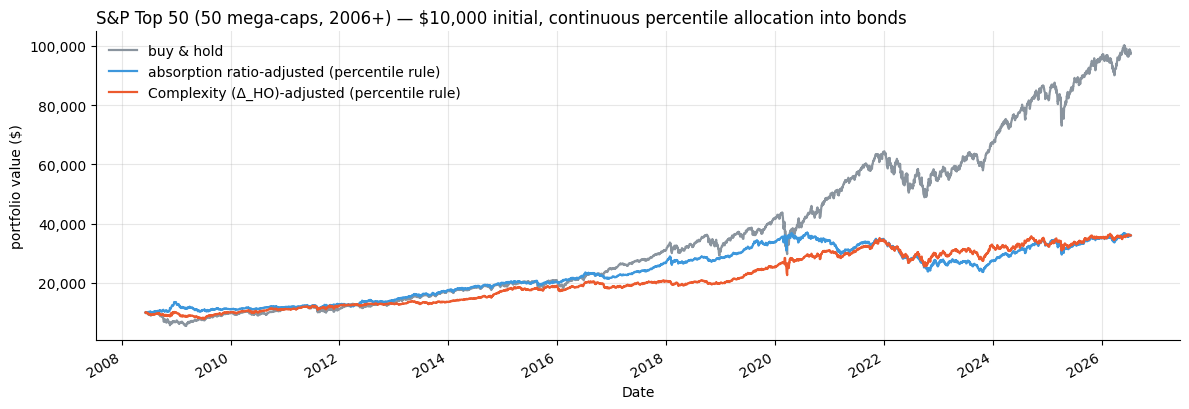

,Average Exposure,Annualized Sharpe Ratio,Maximum Drawdown
Portfolio Management Strategy,,,
Buy and hold,100%,0.64,-46%
absorption ratio-adjusted,48%,0.59,-36%
Complexity (Δ_HO)-adjusted,44%,0.56,-27%
absorption ratio 0/50/100 (Kritzman),51%,0.66,-34%
Complexity (Δ_HO) 0/50/100 (Kritzman),49%,0.50,-31%


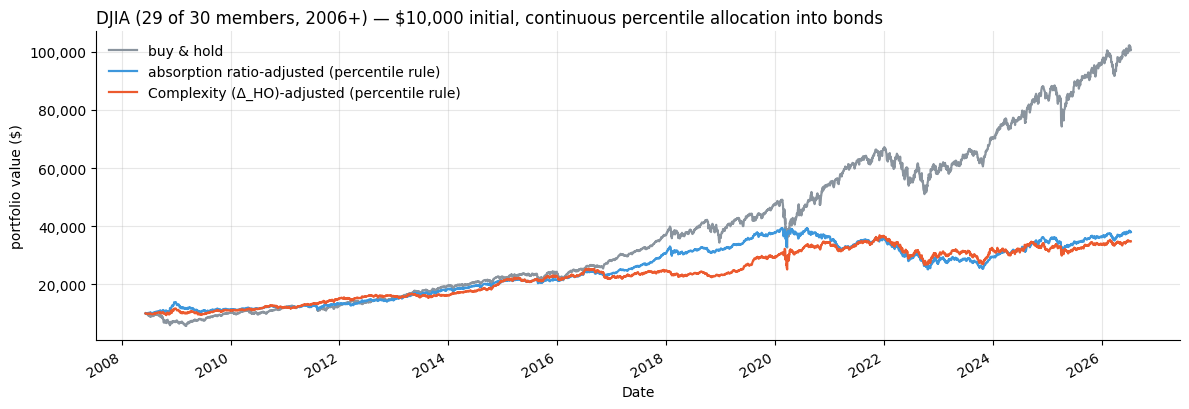

,Average Exposure,Annualized Sharpe Ratio,Maximum Drawdown
Portfolio Management Strategy,,,
Buy and hold,100%,0.67,-43%
absorption ratio-adjusted,51%,0.62,-36%
Complexity (Δ_HO)-adjusted,34%,0.55,-28%
absorption ratio 0/50/100 (Kritzman),51%,0.61,-36%
Complexity (Δ_HO) 0/50/100 (Kritzman),48%,0.61,-28%


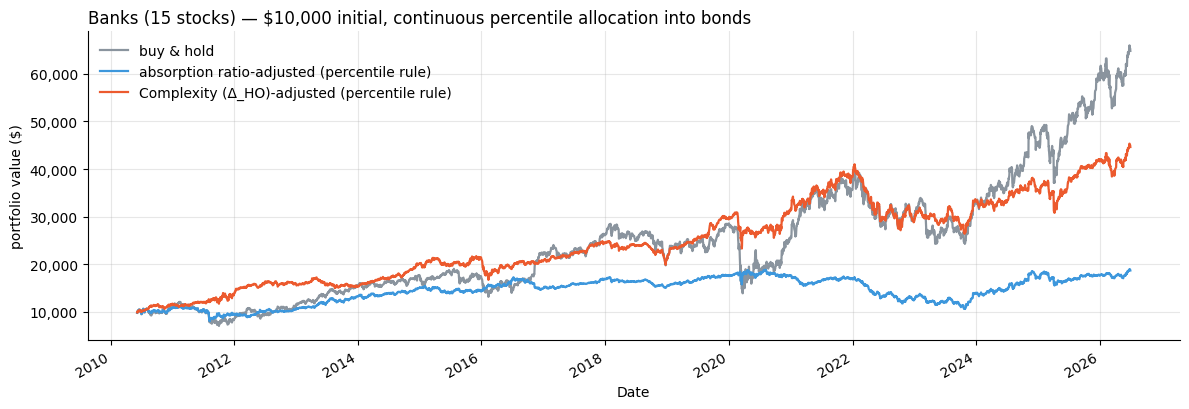

,Average Exposure,Annualized Sharpe Ratio,Maximum Drawdown
Portfolio Management Strategy,,,
Buy and hold,100%,0.42,-51%
absorption ratio-adjusted,38%,0.27,-44%
Complexity (Δ_HO)-adjusted,45%,0.59,-36%
absorption ratio 0/50/100 (Kritzman),52%,0.42,-42%
Complexity (Δ_HO) 0/50/100 (Kritzman),49%,0.50,-30%


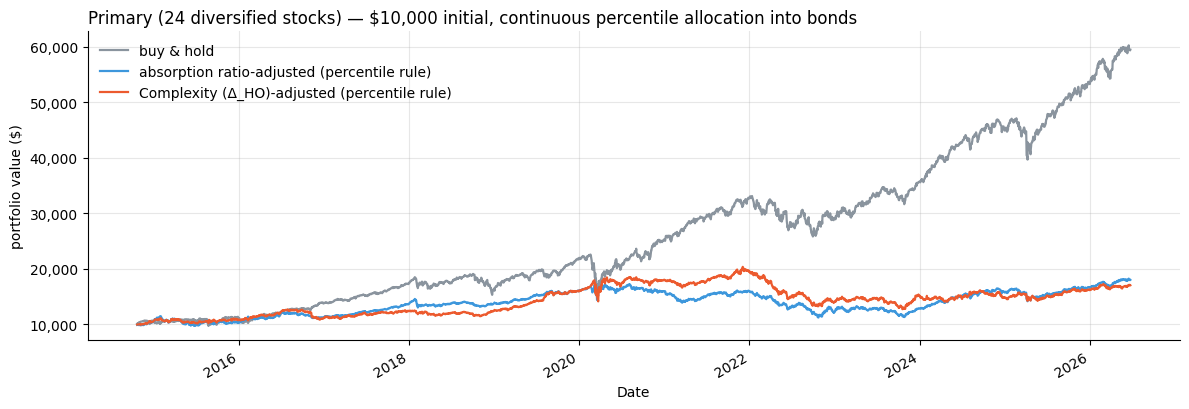

,Average Exposure,Annualized Sharpe Ratio,Maximum Drawdown
Portfolio Management Strategy,,,
Buy and hold,100%,0.91,-33%
absorption ratio-adjusted,40%,0.41,-35%
Complexity (Δ_HO)-adjusted,30%,0.33,-37%
absorption ratio 0/50/100 (Kritzman),50%,0.51,-35%
Complexity (Δ_HO) 0/50/100 (Kritzman),50%,0.73,-28%


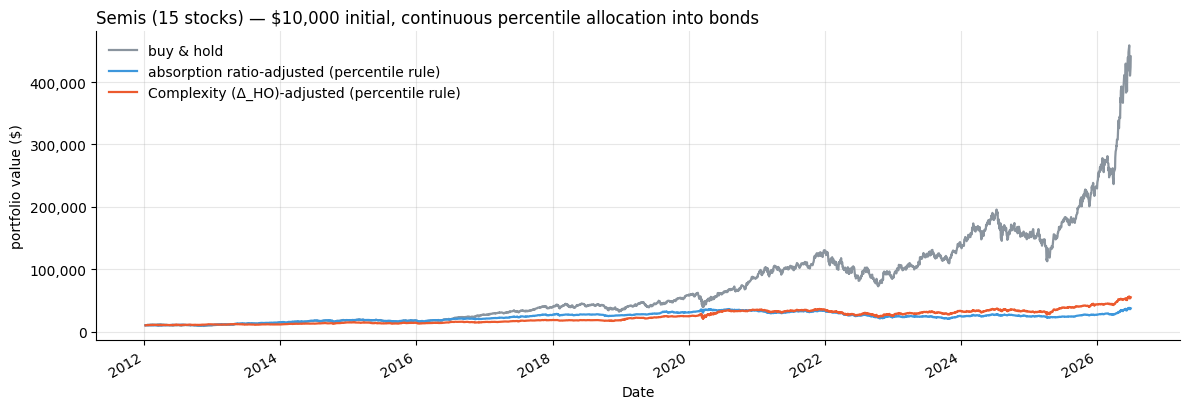

,Average Exposure,Annualized Sharpe Ratio,Maximum Drawdown
Portfolio Management Strategy,,,
Buy and hold,100%,0.85,-44%
absorption ratio-adjusted,38%,0.59,-44%
Complexity (Δ_HO)-adjusted,34%,0.62,-36%
absorption ratio 0/50/100 (Kritzman),47%,0.57,-41%
Complexity (Δ_HO) 0/50/100 (Kritzman),49%,0.75,-41%


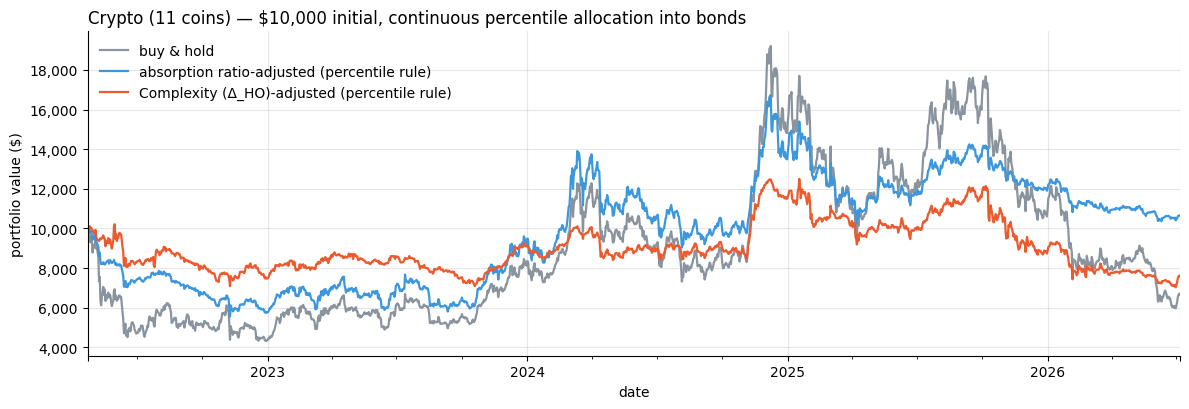

,Average Exposure,Annualized Sharpe Ratio,Maximum Drawdown
Portfolio Management Strategy,,,
Buy and hold,100%,-0.13,-69%
absorption ratio-adjusted,58%,0.03,-45%
Complexity (Δ_HO)-adjusted,32%,-0.20,-44%
absorption ratio 0/50/100 (Kritzman),45%,-0.13,-48%
Complexity (Δ_HO) 0/50/100 (Kritzman),48%,-0.12,-55%


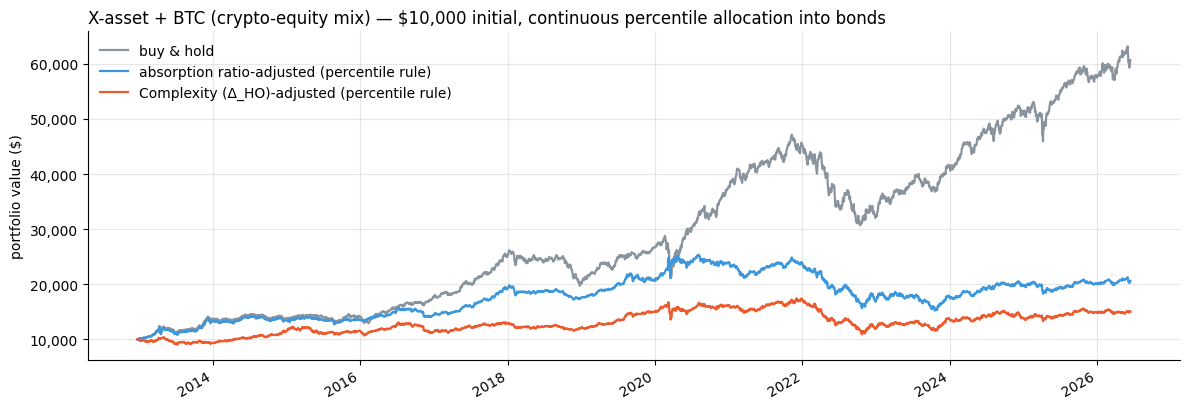

,Average Exposure,Annualized Sharpe Ratio,Maximum Drawdown
Portfolio Management Strategy,,,
Buy and hold,100%,1.01,-35%
absorption ratio-adjusted,51%,0.45,-40%
Complexity (Δ_HO)-adjusted,28%,0.26,-37%
absorption ratio 0/50/100 (Kritzman),54%,0.64,-39%
Complexity (Δ_HO) 0/50/100 (Kritzman),47%,0.44,-39%


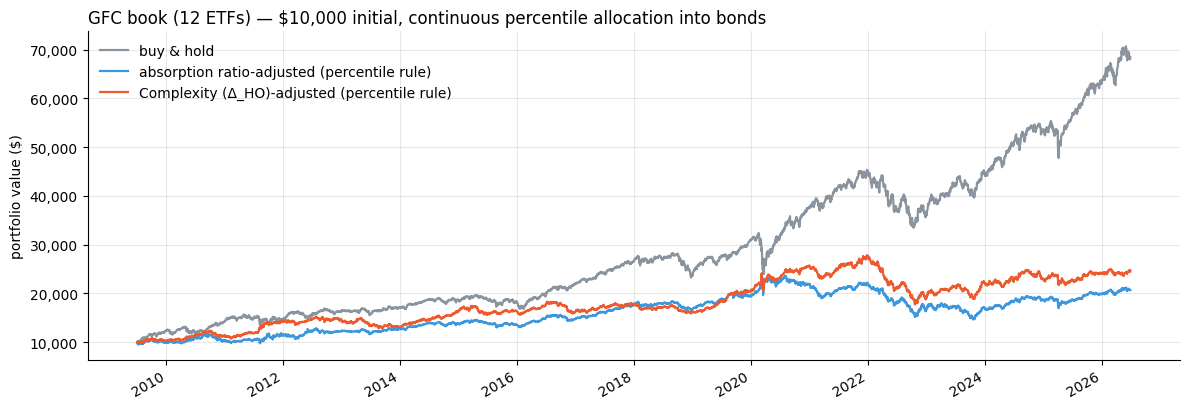

,Average Exposure,Annualized Sharpe Ratio,Maximum Drawdown
Portfolio Management Strategy,,,
Buy and hold,100%,0.86,-26%
absorption ratio-adjusted,50%,0.35,-38%
Complexity (Δ_HO)-adjusted,29%,0.45,-36%
absorption ratio 0/50/100 (Kritzman),49%,0.40,-36%
Complexity (Δ_HO) 0/50/100 (Kritzman),46%,0.51,-33%


final value ($)  \
book                              strategy                                                 
S&P Top 50 (50 mega-caps, 2006+)  Buy and hold                                97,541.116   
                                  absorption ratio-adjusted                   35,891.164   
                                  Complexity (Δ_HO)-adjusted                  35,968.444   
                                  absorption ratio 0/50/100 (Kritzman)        51,591.785   
                                  Complexity (Δ_HO) 0/50/100 (Kritzman)       31,754.897   
DJIA (29 of 30 members, 2006+)    Buy and hold                               100,629.823   
                                  absorption ratio-adjusted                   37,897.774   
                                  Complexity (Δ_HO)-adjusted                  34,715.820   
                                  absorption ratio 0/50/100 (Kritzman)        44,651.780   
                                  Complexity (Δ_HO) 0/50/100 (Kritzman)       41,183.963   
Banks (15 stocks)                 Buy and hold                                64,822.822   
                                  absorption ratio-adjusted                   18,664.225   
                                  Complexity (Δ_HO)-adjusted                  44,623.680   
                                  absorption ratio 0/50/100 (Kritzman)        34,473.976   
                                  Complexity (Δ_HO) 0/50/100 (Kritzman)       39,562.020   
Primary (24 diversified stocks)   Buy and hold                                59,526.897   
                                  absorption ratio-adjusted                   18,030.532   
                                  Complexity (Δ_HO)-adjusted                  17,052.500   
                                  absorption ratio 0/50/100 (Kritzman)        21,697.263   
                                  Complexity (Δ_HO) 0/50/100 (Kritzman)       31,342.073   
Semis (15 stocks)                 Buy and hold                               440,948.272   
                                  absorption ratio-adjusted                   37,155.555   
                                  Complexity (Δ_HO)-adjusted                  54,927.766   
                                  absorption ratio 0/50/100 (Kritzman)        48,899.379   
                                  Complexity (Δ_HO) 0/50/100 (Kritzman)       80,155.181   
Crypto (11 coins)                 Buy and hold                                 6,670.777   
                                  absorption ratio-adjusted                   10,650.224   
                                  Complexity (Δ_HO)-adjusted                   7,590.387   
                                  absorption ratio 0/50/100 (Kritzman)         7,960.082   
                                  Complexity (Δ_HO) 0/50/100 (Kritzman)        8,137.958   
X-asset + BTC (crypto-equity mix) Buy and hold                                60,661.991   
                                  absorption ratio-adjusted                   20,630.785   
                                  Complexity (Δ_HO)-adjusted                  15,088.962   
                                  absorption ratio 0/50/100 (Kritzman)        30,589.175   
                                  Complexity (Δ_HO) 0/50/100 (Kritzman)       19,213.903   
GFC book (12 ETFs)                Buy and hold                                68,398.628   
                                  absorption ratio-adjusted                   20,691.048   
                                  Complexity (Δ_HO)-adjusted                  24,525.100   
                                  absorption ratio 0/50/100 (Kritzman)        23,980.138   
                                  Complexity (Δ_HO) 0/50/100 (Kritzman)       26,862.241   

                                                                          CAGR  \
book                              strategy                                       
S&P Top 50 (50 mega-caps, 2006+)  Buy and ho

In [5]:

# --- exposure rules ---
def blog_exposure(sig):
    # blog Figure-3 rule: w = 1 - expanding percentile rank of the signal (min 1y history)
    r_ = sig.expanding(LOOKBACK).apply(lambda w: (w[:-1] <= w[-1]).mean(), raw=True)
    return 1.0 - r_

def kritzman_exposure(sig):
    # Kritzman standardized shift: fast (15d-equiv) minus slow (1y) average over slow std
    fast = sig.rolling(max(2, LOOKBACK // 17)).mean()
    slow = sig.rolling(LOOKBACK).mean()
    zz = (fast - slow) / sig.rolling(LOOKBACK).std()
    expo = pd.Series(0.5, index=sig.index)
    expo[zz > 1] = 0.0
    expo[zz < -1] = 1.0
    expo[zz.isna()] = np.nan
    return expo

BOND = np.log(pd.read_parquet(DATA / 'combined_gfc_2026.parquet')['TLT'].astype(float)).diff()

def run_dial(ew, sig, rule):
    expo = rule(sig)
    rebal = sig.index[::REBAL_EVERY]
    expo_d = expo.reindex(rebal).reindex(ew.index, method='ffill').shift(1)
    bond = BOND.reindex(ew.index).fillna(0.0)
    return (ew * expo_d + bond * (1 - expo_d)).dropna(), expo_d

def perf(daily, name, avg_expo=1.0):
    ann = 252
    wealth = START_VALUE * np.exp(daily.cumsum())
    return {'strategy': name,
            'final value ($)': float(wealth.iloc[-1]),
            'CAGR': np.expm1(daily.mean() * ann),
            'ann. vol': daily.std() * np.sqrt(ann),
            'Sharpe': daily.mean() / daily.std() * np.sqrt(ann),
            'max drawdown': float((wealth / wealth.cummax() - 1).min()),
            'avg exposure': avg_expo}

from IPython.display import display
all_stats = []
for name, dd in loaded.items():
    ew, g, c = dd['ew'], dd['gauge'], dd['cousin']
    common = g.index.intersection(c.index)
    g_b = run_dial(ew, g.loc[common], blog_exposure)
    c_b = run_dial(ew, c.loc[common], blog_exposure)
    g_k = run_dial(ew, g.loc[common], kritzman_exposure)
    c_k = run_dial(ew, c.loc[common], kritzman_exposure)
    start = max(v[0].index[0] for v in (g_b, c_b, g_k, c_k))
    bh = ew.loc[start:]

    fig, ax = plt.subplots(figsize=(12, 4.2))
    (START_VALUE * np.exp(bh.cumsum())).plot(ax=ax, color=GREY, lw=1.6, label='buy & hold')
    (START_VALUE * np.exp(c_b[0].loc[start:].cumsum())).plot(ax=ax, color=BLUE, lw=1.6,
        label=COUSIN_NAME + '-adjusted (percentile rule)')
    (START_VALUE * np.exp(g_b[0].loc[start:].cumsum())).plot(ax=ax, color=CORAL, lw=1.6,
        label=GAUGE_NAME + '-adjusted (percentile rule)')
    ax.set_ylabel('portfolio value ($)'); ax.legend(loc='upper left', frameon=False)
    ax.set_title(name + ' — $10,000 initial, continuous percentile allocation into bonds', loc='left')
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter('{x:,.0f}'))
    plt.tight_layout(); plt.show()

    book_rows = []
    specs = [(bh, 'Buy and hold', pd.Series(1.0, index=bh.index)),
             (c_b[0].loc[start:], COUSIN_NAME + '-adjusted', c_b[1]),
             (g_b[0].loc[start:], GAUGE_NAME + '-adjusted', g_b[1]),
             (c_k[0].loc[start:], COUSIN_NAME + ' 0/50/100 (Kritzman)', c_k[1]),
             (g_k[0].loc[start:], GAUGE_NAME + ' 0/50/100 (Kritzman)', g_k[1])]
    for daily, lbl, expo_s in specs:
        row = perf(daily, lbl, float(expo_s.loc[start:].mean()))
        row['book'] = name; all_stats.append(row); book_rows.append(row)

    bt = pd.DataFrame(book_rows).set_index('strategy')
    bt = bt[['avg exposure', 'Sharpe', 'max drawdown']]
    bt.columns = ['Average Exposure', 'Annualized Sharpe Ratio', 'Maximum Drawdown']
    bt.index.name = 'Portfolio Management Strategy'
    display(bt.style.format({'Average Exposure': '{:.0%}', 'Annualized Sharpe Ratio': '{:.2f}',
                             'Maximum Drawdown': '{:.0%}'})
              .set_caption(name + ' — portfolio management strategies')
              .set_table_styles([{'selector': 'caption',
                                  'props': [('font-weight', 'bold'), ('font-size', '13px'),
                                            ('text-align', 'left'), ('padding-bottom', '6px')]}]))

tbl = pd.DataFrame(all_stats).set_index(['book', 'strategy'])
tbl[['final value ($)', 'CAGR', 'ann. vol', 'Sharpe', 'max drawdown', 'avg exposure']]


## 6 — A turbulence index of global financial markets — and its MPS fragility twin

Mirroring Figure 1 of the portfoliooptimizer.io turbulence post: the Mahalanobis turbulence index
$d_t = (r_t-\mu)^\top \Sigma^{-1} (r_t-\mu)$ computed daily on a global multi-asset universe —
our GFC book: US equities (broad, small-cap), international developed and emerging equities,
long Treasuries, investment-grade and high-yield credit, REITs, gold, and commodities — with the
familiar crisis spikes. Below it, the same chart with the same treatment for **our gauge**: the MPS
Fragility/Complexity index — the raw **daily** Δ_HO on the same universe and sample, in its own
units (nats/day of beyond-covariance predictive structure), with a 21-day average overlaid. Both
panels are daily raw index values with identical crisis shading; the units differ (a Mahalanobis
distance vs a log-likelihood contrast) but the presentation is like-for-like.

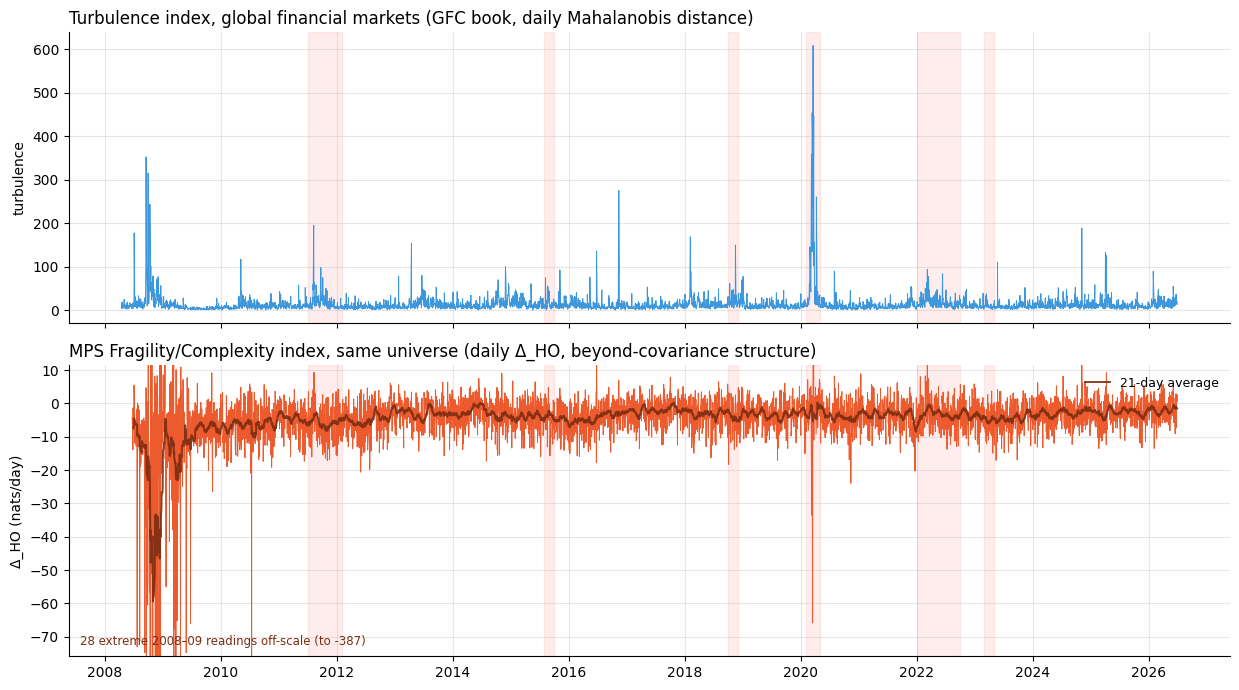

turbulence     latest reading: 67th percentile of its own history
MPS fragility  latest reading: 83th percentile of its own history


In [6]:
gfc_rets = load_returns('combined_gfc_2026')
X = gfc_rets.to_numpy()
turb = np.full(len(gfc_rets), np.nan)
for t in range(252, len(gfc_rets)):
    ref = X[t-252:t]
    mu, C = ref.mean(0), np.cov(ref.T)
    try: inv = np.linalg.inv(C)
    except np.linalg.LinAlgError: inv = np.linalg.pinv(C)
    x = X[t] - mu
    turb[t] = x @ inv @ x
turb = pd.Series(turb, index=gfc_rets.index).dropna()
dhi_gfc = pd.read_csv(RES / 'dhi_combined_gfc_2026_delta.csv', parse_dates=['date']).set_index('date')
frag_raw = dhi_gfc['delta_ho'].dropna()          # raw daily index, same treatment as turbulence
frag_sm = dhi_gfc['delta_ho_sm'].dropna()

fig, (a1, a2) = plt.subplots(2, 1, figsize=(12.5, 7), sharex=True)
a1.plot(turb.index, turb.values, color=BLUE, lw=.7)
a1.set_title('Turbulence index, global financial markets (GFC book, daily Mahalanobis distance)', loc='left')
a1.set_ylabel('turbulence')
a2.plot(frag_raw.index, frag_raw.values, color=CORAL, lw=.7)
a2.plot(frag_sm.index, frag_sm.values, color='#7c2d12', lw=1.4, alpha=.9, label='21-day average')
a2.set_title('MPS Fragility/Complexity index, same universe (daily Δ_HO, beyond-covariance structure)', loc='left')
a2.set_ylabel('Δ_HO (nats/day)'); a2.legend(loc='upper right', frameon=False, fontsize=9)
lo_q, hi_q = frag_raw.quantile(.003), frag_raw.quantile(.997)
a2.set_ylim(lo_q, hi_q)
n_off = int(((frag_raw < lo_q) | (frag_raw > hi_q)).sum())
a2.annotate(f'{n_off} extreme 2008–09 readings off-scale (to {frag_raw.min():.0f})',
            xy=(0.01, 0.04), xycoords='axes fraction', fontsize=8.5, color='#7c2d12')
for ax in (a1, a2): shade(ax)
plt.tight_layout(); plt.show()
for label, ts in (('turbulence', turb), ('MPS fragility', frag_raw)):
    pct = (ts <= ts.iloc[-1]).mean() * 100
    print(f'{label:14s} latest reading: {pct:.0f}th percentile of its own history')

## 7 — The parity books: the designed stress test of the beyond-covariance channel

Three books were engineered in week 5 so that economically-linked triplets hide structure from
pairwise correlation (refiner ≈ products − crude; airline ≈ business − fuel; miner ≈ metal − costs;
bank ≈ curve): **parity-energy**, **parity-metals**, **parity-rates/banks**. If Δ_HO has a natural
habitat, it is here. (Context from the week-5 parity hunt: the third-moment screen found no
XOR-type sign structure in these daily books — a theorem explains why additive identities cannot
produce it — so the honest expectation is *moderate* Δ_HO, not fireworks.)

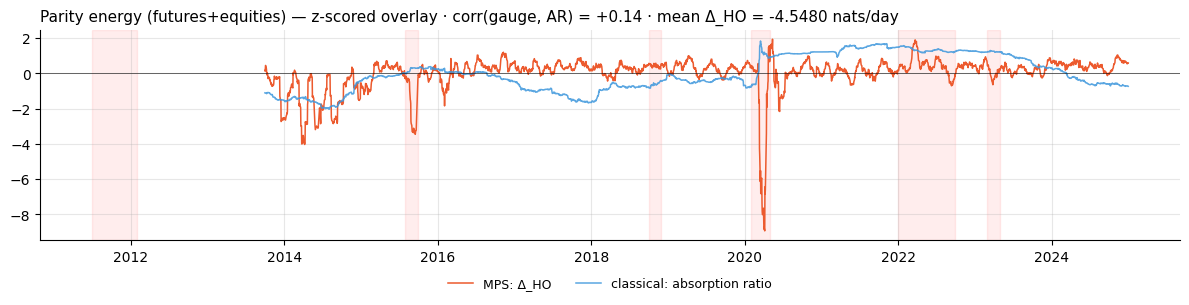

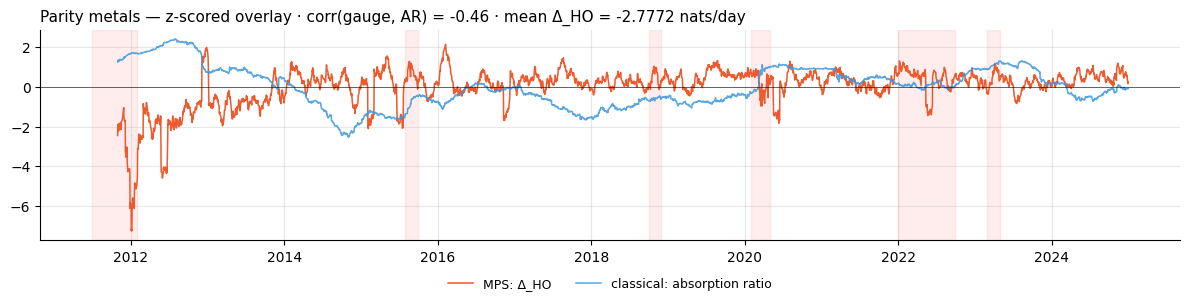

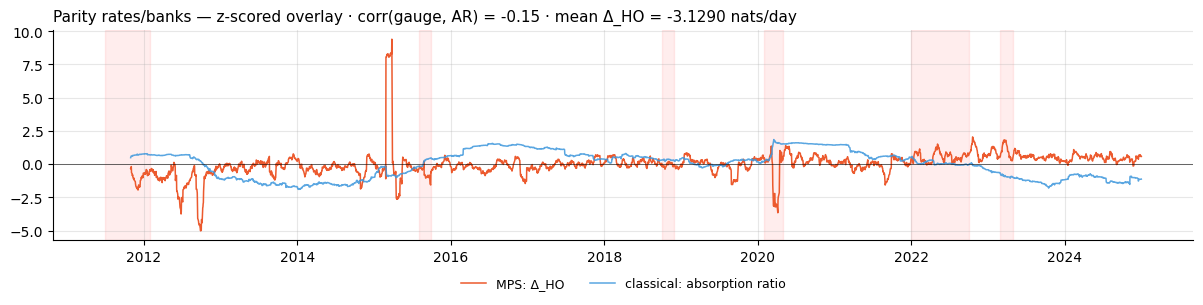

In [7]:
PARITY = {
    'Parity energy (futures+equities)': ('parity_energy_prices', 'dhi_parity_energy_prices_delta'),
    'Parity metals': ('parity_metals_prices', 'dhi_parity_metals_prices_delta'),
    'Parity rates/banks': ('parity_rates_banks_prices', 'dhi_parity_rates_banks_prices_delta'),
}
for name, (stem, dhi_stem) in PARITY.items():
    rets = load_returns(stem)
    gauge = pd.read_csv(RES / f'{dhi_stem}.csv', parse_dates=['date']).set_index('date')[GAUGE_COL].dropna()
    X = rets.to_numpy(); n_eig = max(1, round(rets.shape[1] / 5))
    vals = np.full(len(rets), np.nan)
    for t in range(WIN, len(rets)):
        ev = np.sort(np.linalg.eigvalsh(np.corrcoef(X[t - WIN:t].T)))[::-1]
        vals[t] = ev[:n_eig].sum() / ev.sum()
    cousin = pd.Series(vals, index=rets.index).dropna()
    common = gauge.index.intersection(cousin.index)
    fig, ax = plt.subplots(figsize=(12, 3.2))
    ax.plot(common, z(gauge.loc[common]).values, color=CORAL, lw=1.1, label='MPS: Δ_HO')
    ax.plot(common, z(cousin.loc[common]).values, color=BLUE, lw=1.1, alpha=.85, label='classical: absorption ratio')
    shade(ax); ax.axhline(0, color='k', lw=.4)
    rho = z(gauge.loc[common]).corr(z(cousin.loc[common]))
    ax.set_title(f'{name} — z-scored overlay · corr(gauge, AR) = {rho:+.2f} · mean Δ_HO = {gauge.mean():+.4f} nats/day', loc='left', fontsize=11)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False, fontsize=9)
    plt.tight_layout(); plt.show()

## 8 — Model governance: does the gauge flag when the covariance stack is inadequate?

The gauge's stated job is telling a risk desk **when correlation-based tools are currently
lying**. Test exactly that: for each book, compute a daily rolling Gaussian 1% VaR on the
equal-weight book (normal quantile from the trailing 252-day mean and standard deviation,
$\mathrm{VaR}_t = \mu_{252} + \Phi^{-1}(0.01)\,\sigma_{252}$), and compare the **breach rate
inside each Δ_HO quartile** (quartiles computed causally, from each date's trailing gauge
history). If the covariance model fails disproportionately when Δ_HO is elevated, the gauge is
doing its job.

In [8]:
from scipy.stats import norm as _norm
Z01 = _norm.ppf(0.01)
rows = []
for name, dd in loaded.items():
    ew, g = dd['ew'], dd['gauge']
    mu = ew.rolling(252).mean(); sd = ew.rolling(252).std()
    var = (mu + Z01 * sd).shift(1)
    breach = (ew < var).astype(float).dropna()
    gd = g.reindex(breach.index, method='ffill')
    # causal quartile of the gauge at each date (expanding history, min 60 obs)
    q = gd.expanding(60).apply(lambda w: (w[:-1] <= w[-1]).mean(), raw=True)
    bucket = pd.cut(q, [0, .25, .5, .75, 1.0], labels=['Q1 (low)', 'Q2', 'Q3', 'Q4 (high)'], include_lowest=True)
    for b in ['Q1 (low)', 'Q2', 'Q3', 'Q4 (high)']:
        m = bucket == b
        if m.sum() > 50:
            rows.append({'book': name, 'Δ_HO bucket': b, 'days': int(m.sum()),
                         '1% VaR breach rate': breach[m].mean()})
vtab = pd.DataFrame(rows).pivot_table(index='book', columns='Δ_HO bucket', values='1% VaR breach rate')
vtab['Q4 / Q1 ratio'] = vtab['Q4 (high)'] / vtab['Q1 (low)']
print('Gaussian 1% VaR breach rate by causal Δ_HO quartile (target: 1%):')
vtab.style.format('{:.2%}') if False else vtab

Gaussian 1% VaR breach rate by causal Δ_HO quartile (target: 1%):


Δ_HO bucket,Q1 (low),Q2,Q3,Q4 (high),Q4 / Q1 ratio
book,,,,,
Banks (15 stocks),0.016,0.022,0.021,0.038,2.379
Crypto (11 coins),0.011,0.020,0.020,NaN,NaN
"DJIA (29 of 30 members, 2006+)",0.064,0.033,0.016,0.013,0.204
GFC book (12 ETFs),0.052,0.018,0.020,0.022,0.424
Primary (24 diversified stocks),0.042,0.033,0.017,0.039,0.936
"S&P Top 50 (50 mega-caps, 2006+)",0.040,0.030,0.021,0.027,0.666
Semis (15 stocks),0.038,0.021,0.018,0.028,0.741
X-asset + BTC (crypto-equity mix),0.023,0.021,0.018,0.024,1.053


## 9 — Forward drawdowns by gauge quartile (descriptive)

The PM decision table: conditional on today's gauge quartile (causal, own history), what did the
**next 63 trading days'** maximum drawdown of the book look like — median and worst — and how does
the same table look for the absorption ratio? Descriptive characterization, in-sample by
construction (Week-7: no forecast claim).

In [9]:
def fwd_max_dd(ew, horizon=63):
    w = np.exp(ew.cumsum())
    out = pd.Series(np.nan, index=ew.index)
    vals = w.values
    for i in range(len(vals) - horizon):
        seg = vals[i:i + horizon + 1] / vals[i]
        out.iloc[i] = (seg / np.maximum.accumulate(seg) - 1).min()
    return out

rows = []
for name, dd in loaded.items():
    ew, g, c = dd['ew'], dd['gauge'], dd['cousin']
    fdd = fwd_max_dd(ew)
    for dial_name, s_ in (('Δ_HO', g), ('absorption ratio', c)):
        sd_ = s_.reindex(fdd.index, method='ffill')
        q = sd_.expanding(60).apply(lambda w: (w[:-1] <= w[-1]).mean(), raw=True)
        bucket = pd.cut(q, [0, .25, .5, .75, 1.0], labels=['Q1', 'Q2', 'Q3', 'Q4'], include_lowest=True)
        joined = pd.DataFrame({'fdd': fdd, 'b': bucket}).dropna()
        for b in ['Q1', 'Q4']:
            seg = joined[joined['b'] == b]['fdd']
            if len(seg) > 50:
                rows.append({'book': name, 'dial': dial_name, 'bucket': b,
                             'median fwd 63d max DD': seg.median(), 'worst': seg.min()})
dtab = pd.DataFrame(rows).set_index(['book', 'dial', 'bucket'])
dtab

median fwd 63d max DD  \
book                              dial             bucket                          
S&P Top 50 (50 mega-caps, 2006+)  Δ_HO             Q1                     -0.074   
                                                   Q4                     -0.042   
                                  absorption ratio Q1                     -0.048   
                                                   Q4                     -0.066   
DJIA (29 of 30 members, 2006+)    Δ_HO             Q1                     -0.075   
                                                   Q4                     -0.044   
                                  absorption ratio Q1                     -0.047   
                                                   Q4                     -0.060   
Banks (15 stocks)                 Δ_HO             Q1                     -0.111   
                                                   Q4                     -0.099   
                                  absorption ratio Q1                     -0.088   
                                                   Q4                     -0.095   
Primary (24 diversified stocks)   Δ_HO             Q1                     -0.049   
                                                   Q4                     -0.054   
                                  absorption ratio Q1                     -0.043   
                                                   Q4                     -0.043   
Semis (15 stocks)                 Δ_HO             Q1                     -0.113   
                                                   Q4                     -0.118   
                                  absorption ratio Q1                     -0.072   
                                                   Q4                     -0.108   
Crypto (11 coins)                 Δ_HO             Q1                     -0.343   
                                  absorption ratio Q1                     -0.195   
X-asset + BTC (crypto-equity mix) Δ_HO             Q1                     -0.038   
                                                   Q4                     -0.049   
                                  absorption ratio Q1                     -0.055   
                                                   Q4                     -0.051   
GFC book (12 ETFs)                Δ_HO             Q1                     -0.088   
                                                   Q4                     -0.040   
                                  absorption ratio Q1                     -0.044   
                                                   Q4                     -0.057   

                                                           worst  
book                              dial             bucket         
S&P Top 50 (50 mega-caps, 2006+)  Δ_HO             Q1     -0.420  
                                                   Q4     -0.195  
                                  absorption ratio Q1     -0.180  
                                                   Q4     -0.209  
DJIA (29 of 30 members, 2006+)    Δ_HO             Q1     -0.248  
                                                   Q4     -0.317  
                                  absorption ratio Q1     -0.335  
                                                   Q4     -0.235  
Banks (15 stocks)                 Δ_HO             Q1     -0.503  
                                                   Q4     -0.427  
                                  absorption ratio Q1     -0.329  
                                                   Q4     -0.300  
Primary (24 diversified stocks)   Δ_HO             Q1     -0.281  
                                                   Q4     -0.171  
                                  absorption ratio Q1     -0.158  
                                                   Q4     -0.241  
Semis (15 stocks)                 Δ_HO             Q1     -0.281  
                                                   Q4     -0.376  
                              

## Reading the portfolio-value results

This gauge's dial-vs-dial contest against the absorption ratio is the fairest in the module —
both are coupling meters consumed identically. The all-books comparison found the higher-order
dial wins on the concentrated stock books and the absorption ratio on the diversified ones,
matching the Week-7 capacity map. Same discipline as everywhere: demonstration protocol,
descriptive gauges, no cost modeling.